In [2]:
import sys
print(sys.version)

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]


In [3]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [4]:
#!pip install pandas numpy matplotlib pydot seaborn scikit-learn tensorflow keras

In [5]:
#pip install scikeras

In [6]:
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

# Evaluation Library
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

# Deep Learning Libraries
import tensorflow as tf
from tensorflow.keras import layers
import keras
from keras.models import Sequential
#from keras.datasets import mnist
#from keras.utils.np_utils import to_categorical
#from keras.wrappers.scikit_learn import KerasClassifier
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from scikeras.wrappers import KerasClassifier

In [7]:
# Load the Dataset
# Digit MNIST dataset
(X_train_digit,y_train_digit),(X_test_digit,y_test_digit)=mnist.load_data()

# mnist
# This is the name of the famous dataset. It contains 70,000 images of handwritten digits (0-9) written by different people. Made by Yann LeCun.

# load_data()
# This function does 2 things in 1 second:

# Downloads the dataset from the internet (first time only)
# Splits it into 2 parts - Training and Testing

In [8]:
X_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [9]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

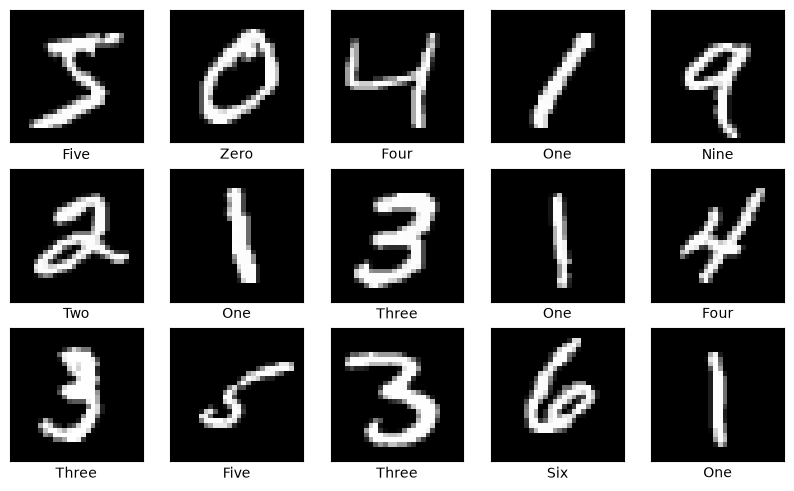

In [10]:
# Names of numbers in the dataset in order
col_names=['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']  # -->This is a list that converts numbers to words.

# Visuaklizing the digits
plt.figure(figsize=(10,10))      # Creates a big blank white paper of size 10x10 inches. All your 15 images will be drawn on this one paper.
for i in range(15):              # Loop. i will go from 0 to 14. So we will show the first 15 images from your dataset.
    plt.subplot(5,5,i+1)         # This divides your big paper into a grid of 5 rows and 5 columns = 25 small boxes.
                                 # i+1 means: 1st loop -> 1st box, 2nd loop -> 2nd box... and so on. You are using only 15 boxes out of 25.
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train_digit[i],cmap='gray') # Show in black&white color(like real handwritten digits).Without this it will show in yellow/blue colors.
    plt.xlabel(col_names[y_train_digit[i]])  # y_train_digit[i] = The true label of that image, e.g. 5
                                             # col_names[5] = Five # So it writes Five below that image.  
plt.show()                       # Finally, display the whole paper with all 15 images. Without this, nothing will appear. 

In [11]:
X_train_digit.shape

(60000, 28, 28)

In [12]:
# The above output is in 3D, but for ANN, the input dimension should be 2D. So, it will be converted to 2D using 'reshape'.
# ANN cannot understand 28x28 image. So you flatten it: 28*28 = 784 pixels in one single line. From 3D to 2D.

In [13]:
X_train_digit=X_train_digit.reshape(60000,784)
X_test_digit=X_test_digit.reshape(10000,784)

In [14]:
X_train_digit.shape

(60000, 784)

In [15]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [16]:
y_test_digit

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

In [17]:
y_test_digit.shape

(10000,)

In [18]:
# The above output should be in categorical format, so it will be converted using 'One-Hot Encoding'
# Computer cannot understand 5 as 10 outputs. So you convert it to:
5 = [0,0,0,0,0,1,0,0,0,0] -> 1 at 5th position. This is called One-Hot Encoding

In [19]:
# Encoding Digit MNIST Labels
y_train_digit=to_categorical(y_train_digit,num_classes=10)
y_test_digit=to_categorical(y_test_digit,num_classes=10)

In [20]:
y_train_digit

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

In [21]:
y_train_digit[1]

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [22]:
# The output of the ANN should be in 'One-Hot Encoding' format.

In [44]:
# Creating base neural network
model=keras.Sequential([layers.Dense(256,activation='relu',input_shape=(784,)),
                        # You must add a comma. (784) is just number 784. (784,) means a tuple with one value.ANN needs shape in tuple form.
                        # 784 comes from 28*28 = 784 pixels.
                        #layers.Dropout(0.3),
                        #layers.BatchNormalization(),
                        layers.Dense(64,activation='relu'),
                        #layers.Dropout(0.3),
                        #layers.BatchNormalization(),
                        layers.Dense(64,activation='relu'),
                        #layers.Dropout(0.3),
                        #layers.BatchNormalization(),
                        layers.Dense(10,activation='softmax'),])    # layers.Dense(10,activation='sigmoid is wrong one so I have replaced it by the new

C:\Users\VijeNeek\.conda\envs\aiml_latest\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [45]:
# param_number=output_channel_number*(input_channel_number+1)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Compiling the model
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=['accuracy'])

In [26]:
# 1. model.compile()
#    You built the model before. Now you are telling it how to learn.

# 2. loss="categorical_crossentropy"
#    Loss = How to calculate the mistake.
#    Your answer is One-Hot like [0,0,0,0,0,1,0...]. For this type, we always use categorical_crossentropy. It checks "How far is your predicted probability from the true answer?" Less mistake = better.

# 3. optimizer="adam"
#    Optimizer = How to correct the mistake.
#    adam is the best and most popular optimizer. It automatically adjusts the learning speed. Think of it as a smart teacher who tells the model how much to change its brain after each mistake.

# 4. metrics=['accuracy']
#    What to show you while learning. You want to see accuracy (%) - how many digits it predicted correctly.

In [48]:
history=model.fit(X_train_digit,y_train_digit,batch_size=100,epochs=10,validation_data=(X_test_digit,y_test_digit))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8497 - loss: 1.4726 - val_accuracy: 0.9069 - val_loss: 0.3628
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9327 - loss: 0.2587 - val_accuracy: 0.9376 - val_loss: 0.2432
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9510 - loss: 0.1755 - val_accuracy: 0.9459 - val_loss: 0.2202
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9609 - loss: 0.1359 - val_accuracy: 0.9472 - val_loss: 0.2147
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9660 - loss: 0.1166 - val_accuracy: 0.9536 - val_loss: 0.1805
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9694 - loss: 0.1066 - val_accuracy: 0.9577 - val_loss: 0.1721
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9725 - loss: 0.0933 - val_accuracy: 0.9629 - val_loss: 0.1533
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9750 - loss: 0.0856 - val_accuracy: 0.

In [49]:
# Predicting the Labels-DIGIT
y_predict=model.predict(X_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [50]:
y_predict

array([[7.0435097e-15, 2.6834002e-09, 1.8188897e-08, ..., 1.0000000e+00,
        2.5164094e-14, 5.7101648e-09],
       [1.5763437e-12, 4.7390117e-06, 9.9995399e-01, ..., 2.4913024e-07,
        1.4732213e-05, 3.5046754e-13],
       [5.7806443e-10, 9.9999595e-01, 2.1319499e-09, ..., 2.5644217e-06,
        1.3383400e-06, 5.6616425e-13],
       ...,
       [8.8189393e-25, 1.1544796e-16, 1.4543729e-19, ..., 6.6609740e-10,
        1.8925772e-15, 9.4971242e-13],
       [1.0209168e-06, 1.4059090e-26, 2.9167632e-17, ..., 1.5347948e-12,
        1.2684762e-12, 5.5517131e-15],
       [1.1872662e-14, 6.1492638e-12, 2.3210824e-09, ..., 2.6408968e-14,
        7.7968347e-11, 2.2311498e-13]], shape=(10000, 10), dtype=float32)

In [51]:
y_predict[0]

array([7.0435097e-15, 2.6834002e-09, 1.8188897e-08, 1.5548503e-08,
       2.7269338e-11, 2.1536353e-14, 3.9583612e-18, 1.0000000e+00,
       2.5164094e-14, 5.7101648e-09], dtype=float32)

In [52]:
# The model outputs 10 probabilities. The index of the highest probability is the predicted digit.
# The position / index of the maximum value is the output.
# predicted_digit = np.argmax(y_predict[0])

In [53]:
y_predicts=np.argmax(y_predict,axis=1)   # Here, we get the index of the maximum value from the encoded vector to find the predicted digit. (Or)
                                         # Get the predicted digit by finding the index of the highest probability in each row  
                                         # np.argmax(y_test_digit, axis=1) converts One-Hot BACK to simple number.

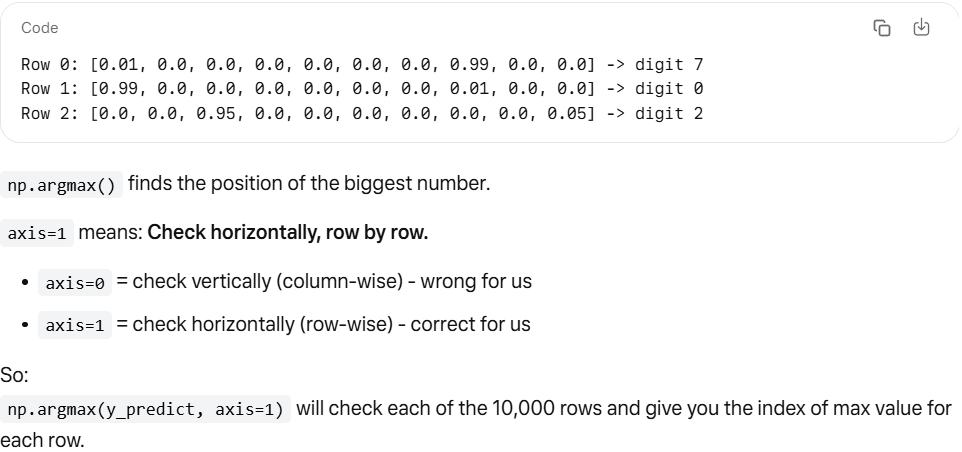

In [54]:
y_predicts     # Test data --> Predicted

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [55]:
y_test_digit_eval=np.argmax(y_test_digit,axis=1)     # Actual test data

In [56]:
y_test_digit_eval

# y_test = It's from the test data, the true answers.
# digit = It's for digit MNIST (0-9).
# eval = Evaluation. Means you are converting it to a format that you can use for evaluation / checking accuracy.
# So full meaning is:

# "The true test digits, converted back to simple numbers for evaluation."

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

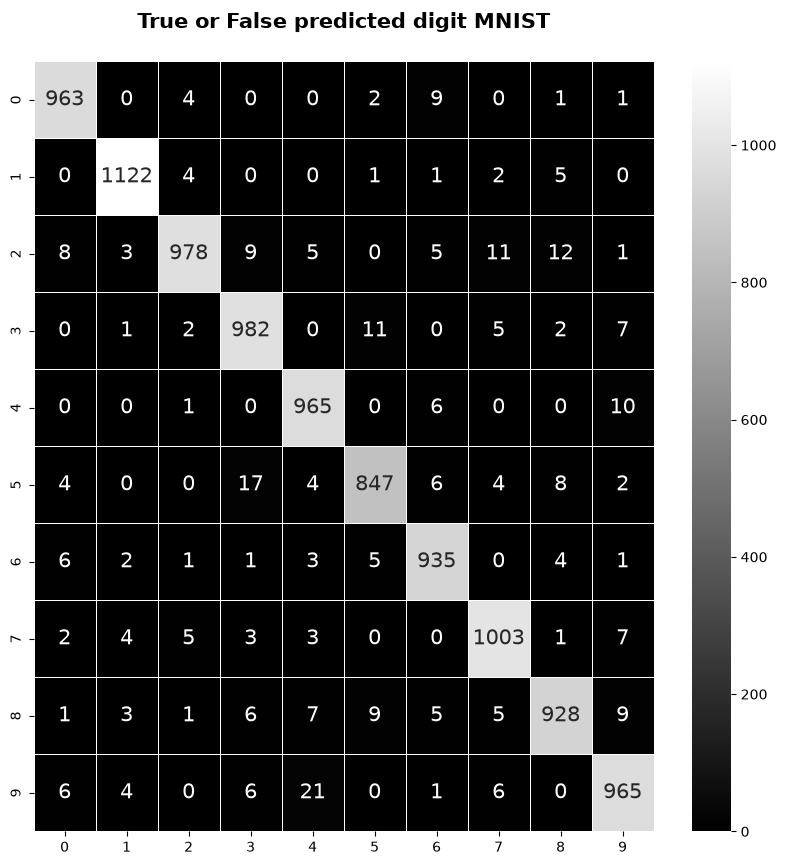

In [57]:
# Confusion Matrix for Digit MNIST
con_mat=confusion_matrix(y_test_digit_eval,y_predicts)
# plt.style.use('seaborn-deep')  # In new matplotlib (version 3.6+), all seaborn-xxx styles were renamed to seaborn-v0_8-xxx. So seaborn-deep does NOT exist anymore.
# plt.style.use('seaborn-v0_8-deep') # new name
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size':15},linewidths=0.5,fmt="d",cmap="gray")
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()

# fmt="d"

fmt = format
"d" = decimal integer (d = digit / decimal)
It tells seaborn: "Show the numbers inside the boxes as simple integers like 980, not as float like 980.0"

Because confusion matrix values are counts:
0, 15, 980, 1023 - they are whole numbers, not decimals.

If you write fmt="f" it would show 980.000000
If you write fmt=".2f" it would show 980.00

fmt="d" is correct for confusion matrix.

In [58]:
from sklearn.metrics import classification_report
print(classification_report(y_test_digit_eval,y_predicts))

              precision    recall  f1-score   support

           0       0.97      0.98      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.95      0.96      1032
           3       0.96      0.97      0.97      1010
           4       0.96      0.98      0.97       982
           5       0.97      0.95      0.96       892
           6       0.97      0.98      0.97       958
           7       0.97      0.98      0.97      1028
           8       0.97      0.95      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [59]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


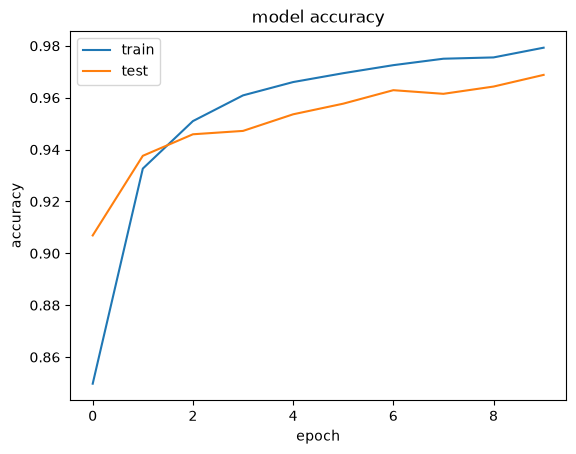

In [60]:
# Summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='best')
plt.show()


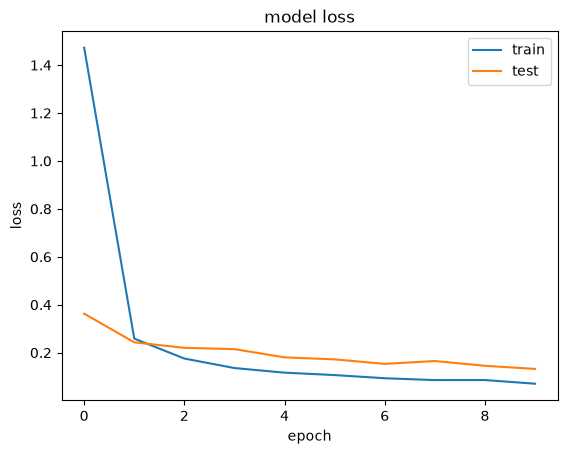

In [61]:
# Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='best')
plt.show()
         

In [62]:
#tf.expand_dims(x_test_digit[0])
y_predict_single=model.predict(X_test_digit[[2]])
y_predicts_single=np.argmax(y_predict_single,axis=1)  # Here, we get the index of the maximum value from the encoded vector to find the predicted digit
y_test_digit_eval=np.argmax(y_test_digit,axis=1)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


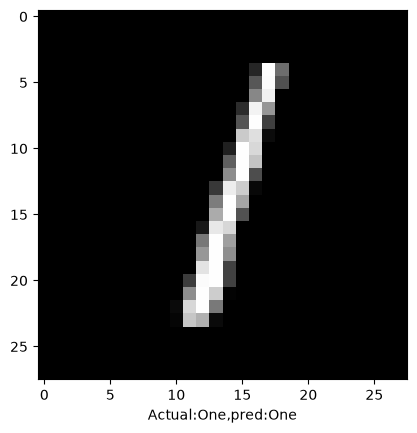

In [63]:
# Names of numbers in the dataset in order
col_names=['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

# Visualizing the digits
#plt.figure(figsize=(10,10))
plt.imshow(X_test_digit[2].reshape(28,28),cmap='gray')
plt.xlabel("Actual:{},pred:{}".format(col_names[np.argmax(y_test_digit[2])],col_names[y_predicts_single[0]]))
plt.show()